# CAP 5410 — Assignment #2: Image Filters

**Name:** Fernando Melo Filho

**Course:** CAP 5410 — Computer Vision

**Due Date:** Saturday, September 26, 2026

This notebook implements and compares box filtering, Sobel edge detection (X, Y, and combined), and Gaussian smoothing — each both from scratch and using OpenCV built-ins, at 3x3 and 5x5 kernel sizes. All exercises use the same input image, loaded once below.

## Setup

Image shape (rows, cols): (361, 410) uint8


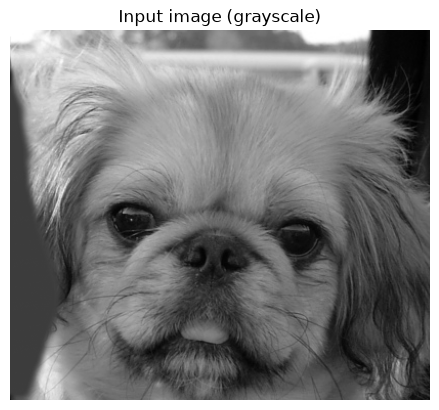

In [1]:
import sys, time
sys.path.append("..")          # so we can import filters.py from the assignment folder

import numpy as np
import cv2
import matplotlib.pyplot as plt
from filters import (box_filter_manual, sobel_x_manual, sobel_y_manual, sobel_xy_manual,
                     box_filter_cv, sobel_xy_cv, gaussian_cv, to_display)

FIG_DIR = "../report/figures/"

img_gray = cv2.imread("../images/dog.bmp", cv2.IMREAD_GRAYSCALE)
print("Image shape (rows, cols):", img_gray.shape, img_gray.dtype)


def show_row(images, titles, filename, zoom=None):
    """Show images side by side and save the figure for the report.
    zoom = (y0, y1, x0, x1) crops every image to the same region."""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4.5))
    for ax, im, t in zip(axes, images, titles):
        if zoom is not None:
            y0, y1, x0, x1 = zoom
            im = im[y0:y1, x0:x1]
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=14)
        ax.axis("off")
    plt.tight_layout()
    fig.savefig(FIG_DIR + filename, dpi=150, bbox_inches="tight")
    plt.show()


plt.imshow(img_gray, cmap="gray"); plt.title("Input image (grayscale)"); plt.axis("off")
plt.savefig(FIG_DIR + "input.png", dpi=150, bbox_inches="tight"); plt.show()


---
## Exercise 1 — Box Filter (Manual Implementation)

Implement your own box (mean) filter — no `cv2.blur` / `cv2.boxFilter`.

### 1.1 — 3x3 Kernel

Apply your manual box filter with a **3x3** kernel.

In [2]:
t0 = time.perf_counter()
box_3x3 = box_filter_manual(img_gray, 3)
print(f"Manual 3x3 box filter: {time.perf_counter() - t0:.2f} s")

Manual 3x3 box filter: 0.31 s


### 1.2 — 5x5 Kernel

Apply your manual box filter with a **5x5** kernel.

Manual 5x5 box filter: 0.30 s


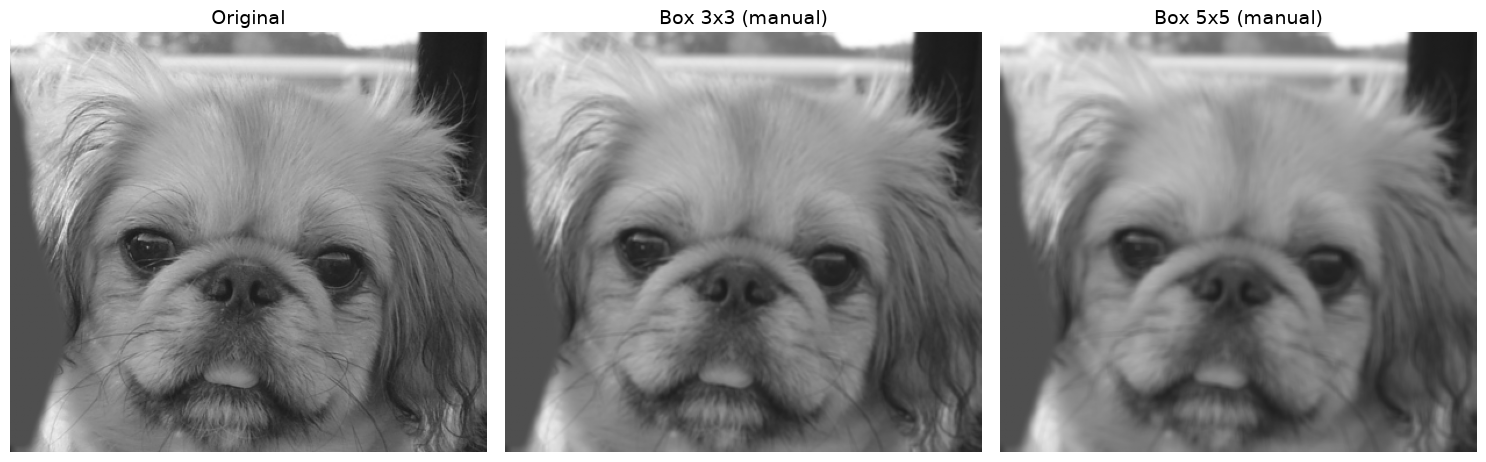

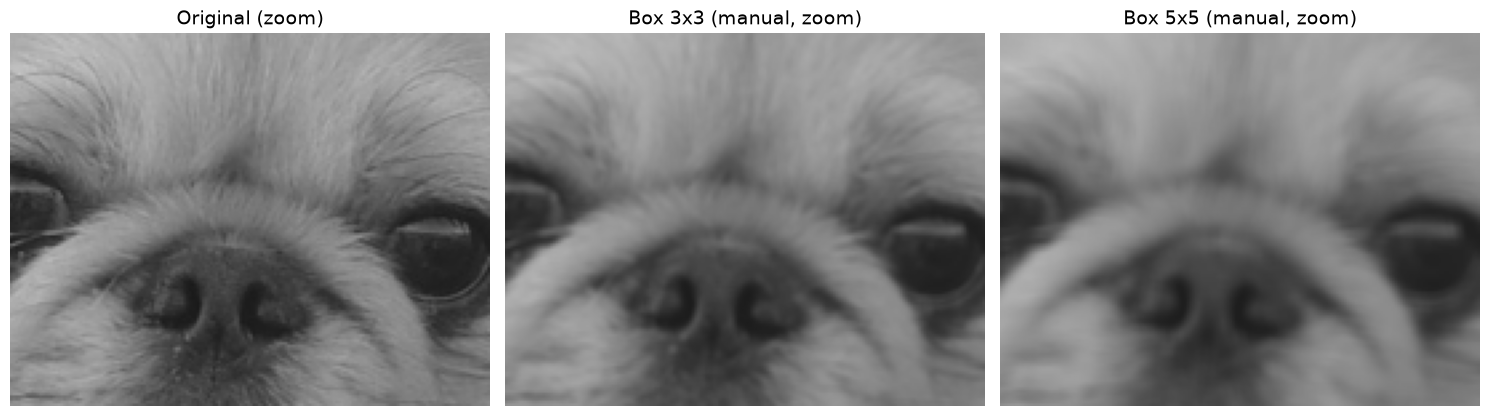

In [3]:
t0 = time.perf_counter()
box_5x5 = box_filter_manual(img_gray, 5)
print(f"Manual 5x5 box filter: {time.perf_counter() - t0:.2f} s")

show_row([img_gray, box_3x3, box_5x5], ["Original", "Box 3x3 (manual)", "Box 5x5 (manual)"], "ex1_box_manual.png")
show_row([img_gray, box_3x3, box_5x5], ["Original (zoom)", "Box 3x3 (manual, zoom)", "Box 5x5 (manual, zoom)"], "ex1_box_manual_zoom.png", zoom=(120, 260, 120, 300))

**Discussion:** Both kernels blur the image. The 5x5 kernel averages 25 pixels instead of 9, so it blurs more (clearer in the zoomed view). Borders are handled by reflect-padding the image with `np.pad`, the same as OpenCV's default.

---
## Exercise 2 — Box Filter (OpenCV)

Apply OpenCV's built-in box filter function.

### 2.1 — 3x3 Kernel

Apply `cv2.blur` / `cv2.boxFilter` with a **3x3** kernel.

In [4]:
t0 = time.perf_counter()
box_cv_3x3 = box_filter_cv(img_gray, 3)
print(f"OpenCV 3x3 box filter: {(time.perf_counter() - t0) * 1000:.3f} ms")
print("Max difference manual vs OpenCV (3x3):", np.abs(box_3x3.astype(int) - box_cv_3x3.astype(int)).max())

OpenCV 3x3 box filter: 2.259 ms
Max difference manual vs OpenCV (3x3): 0


### 2.2 — 5x5 Kernel

Apply `cv2.blur` / `cv2.boxFilter` with a **5x5** kernel.

OpenCV 5x5 box filter: 0.183 ms
Max difference manual vs OpenCV (5x5): 0


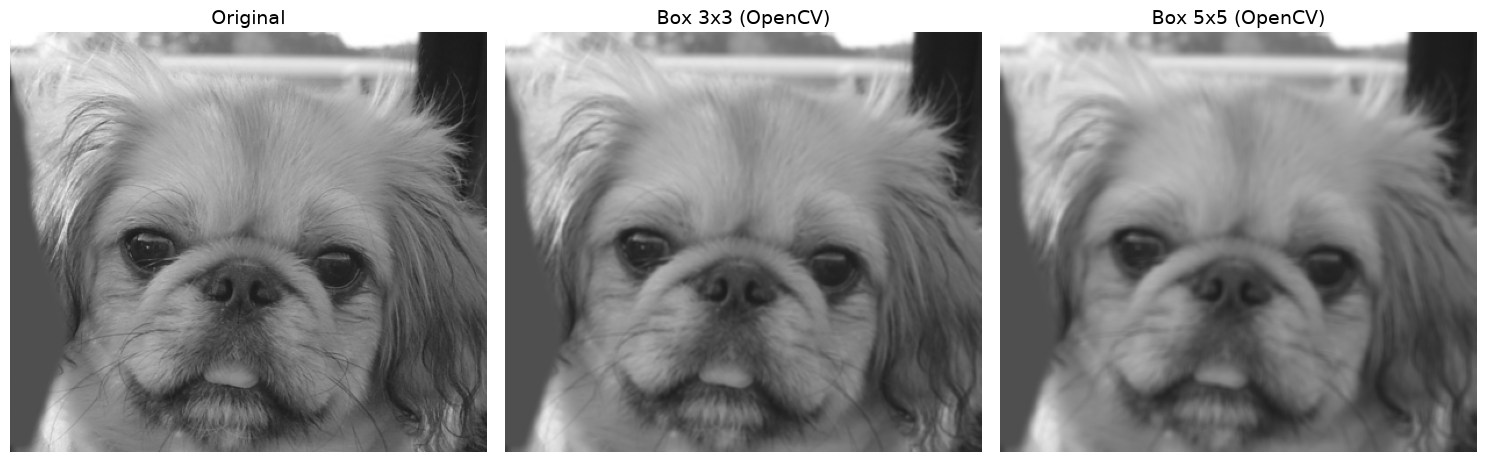

In [5]:
t0 = time.perf_counter()
box_cv_5x5 = box_filter_cv(img_gray, 5)
print(f"OpenCV 5x5 box filter: {(time.perf_counter() - t0) * 1000:.3f} ms")
print("Max difference manual vs OpenCV (5x5):", np.abs(box_5x5.astype(int) - box_cv_5x5.astype(int)).max())

show_row([img_gray, box_cv_3x3, box_cv_5x5], ["Original", "Box 3x3 (OpenCV)", "Box 5x5 (OpenCV)"], "ex2_box_opencv.png")

**Discussion:** The OpenCV result is identical to my manual filter (max difference 0). The only difference is speed: `cv2.blur` takes under 1 ms, my Python loop about 0.3 s.

---
## Exercise 3 — Sobel Filter — X-axis Edges (Manual Implementation)

Implement your own Sobel filter for X-axis edges — no `cv2.Sobel`.

### 3.1 — 3x3 Kernel

Apply your manual Sobel-X filter with a **3x3** kernel.

In [6]:
sobel_x_3x3 = sobel_x_manual(img_gray, 3)
print("Gx 3x3 range:", sobel_x_3x3.min(), "to", sobel_x_3x3.max())

Gx 3x3 range: -470.0 to 465.0


### 3.2 — 5x5 Kernel

Apply your manual Sobel-X filter with a **5x5** kernel.

Gx 5x5 range: -6032.0 to 4994.0


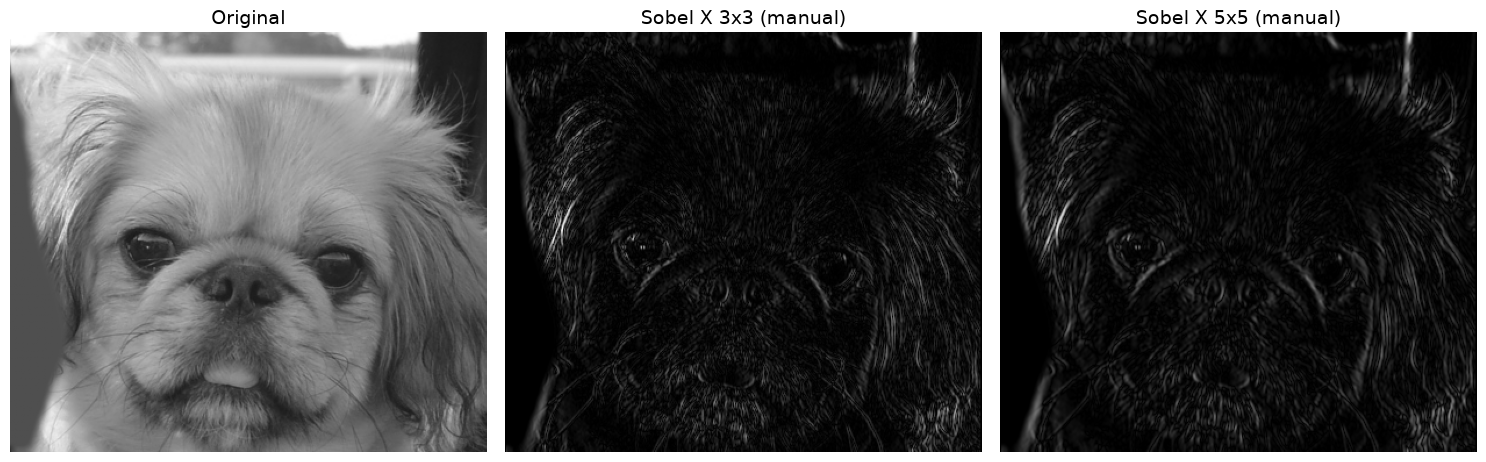

In [7]:
sobel_x_5x5 = sobel_x_manual(img_gray, 5)
print("Gx 5x5 range:", sobel_x_5x5.min(), "to", sobel_x_5x5.max())

show_row([img_gray, to_display(sobel_x_3x3), to_display(sobel_x_5x5)],
         ["Original", "Sobel X 3x3 (manual)", "Sobel X 5x5 (manual)"], "ex3_sobel_x.png")

**Discussion:** Sobel X highlights vertical edges (sides of the face, fur strands, the post in the background). The 3x3 kernel gives thin edges with more texture noise; the 5x5 kernel gives thicker, smoother edges because it also smooths over a wider area.

---
## Exercise 4 — Sobel Filter — Y-axis Edges (Manual Implementation)

Implement your own Sobel filter for Y-axis edges — no `cv2.Sobel`.

### 4.1 — 3x3 Kernel

Apply your manual Sobel-Y filter with a **3x3** kernel.

In [8]:
sobel_y_3x3 = sobel_y_manual(img_gray, 3)
print("Gy 3x3 range:", sobel_y_3x3.min(), "to", sobel_y_3x3.max())

Gy 3x3 range: -428.0 to 459.0


### 4.2 — 5x5 Kernel

Apply your manual Sobel-Y filter with a **5x5** kernel.

Gy 5x5 range: -4611.0 to 4669.0


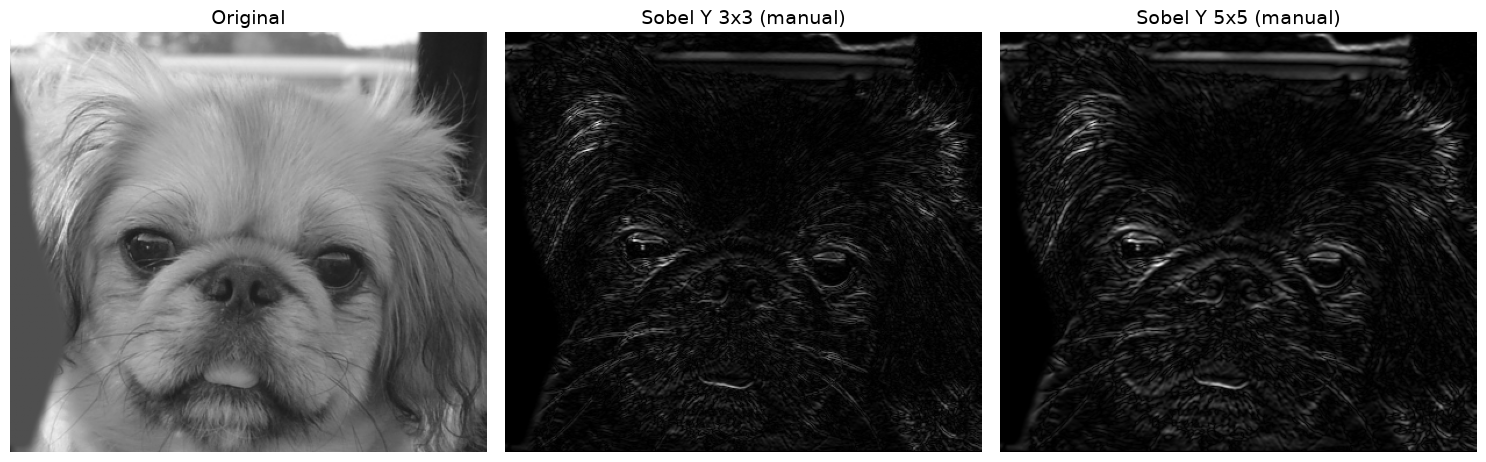

In [9]:
sobel_y_5x5 = sobel_y_manual(img_gray, 5)
print("Gy 5x5 range:", sobel_y_5x5.min(), "to", sobel_y_5x5.max())

show_row([img_gray, to_display(sobel_y_3x3), to_display(sobel_y_5x5)],
         ["Original", "Sobel Y 3x3 (manual)", "Sobel Y 5x5 (manual)"], "ex4_sobel_y.png")

**Discussion:** Sobel Y is the opposite: it highlights horizontal edges (the bar in the background, eyes, nose, mouth), while vertical edges become weak. Again 5x5 is smoother than 3x3.

---
## Exercise 5 — Sobel Filter — X + Y Edges (Manual Implementation)

Combine your manual Sobel-X and Sobel-Y results (no `cv2.Sobel`) into a combined edge magnitude image.

### 5.1 — 3x3 Kernel

Combine X and Y Sobel edges with a **3x3** kernel.

In [10]:
sobel_xy_3x3 = sobel_xy_manual(img_gray, 3)
print("Magnitude 3x3 max:", sobel_xy_3x3.max())

Magnitude 3x3 max: 486.59634195090285


### 5.2 — 5x5 Kernel

Combine X and Y Sobel edges with a **5x5** kernel.

Magnitude 5x5 max: 6032.0


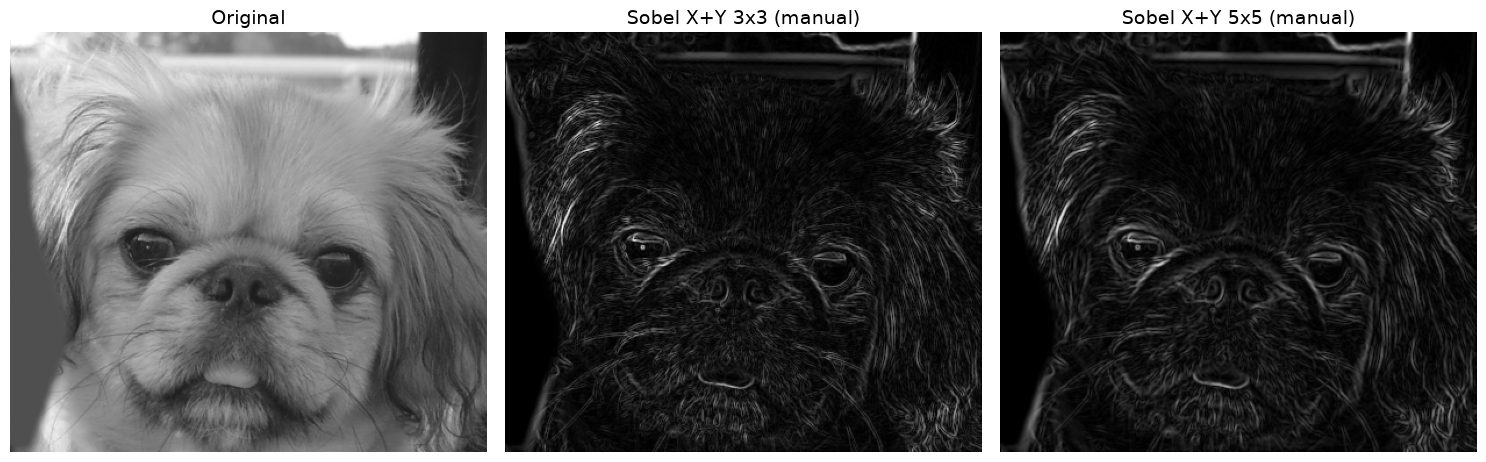

In [11]:
sobel_xy_5x5 = sobel_xy_manual(img_gray, 5)
print("Magnitude 5x5 max:", sobel_xy_5x5.max())

show_row([img_gray, to_display(sobel_xy_3x3), to_display(sobel_xy_5x5)],
         ["Original", "Sobel X+Y 3x3 (manual)", "Sobel X+Y 5x5 (manual)"], "ex5_sobel_xy.png")

**Discussion:** Combining both directions with sqrt(Gx^2 + Gy^2) gives a complete edge map, independent of edge direction.

---
## Exercise 6 — Sobel Filter — X + Y Edges (OpenCV)

Use `cv2.Sobel` for X and Y directions and combine them into a single edge image.

### 6.1 — 3x3 Kernel

Apply `cv2.Sobel` (X and Y) with a **3x3** kernel and combine.

In [12]:
sobel_xy_cv_3x3 = sobel_xy_cv(img_gray, 3)
print("Max difference manual vs OpenCV (3x3):", np.abs(sobel_xy_3x3 - sobel_xy_cv_3x3).max())

Max difference manual vs OpenCV (3x3): 0.0


### 6.2 — 5x5 Kernel

Apply `cv2.Sobel` (X and Y) with a **5x5** kernel and combine.

Max difference manual vs OpenCV (5x5): 0.0


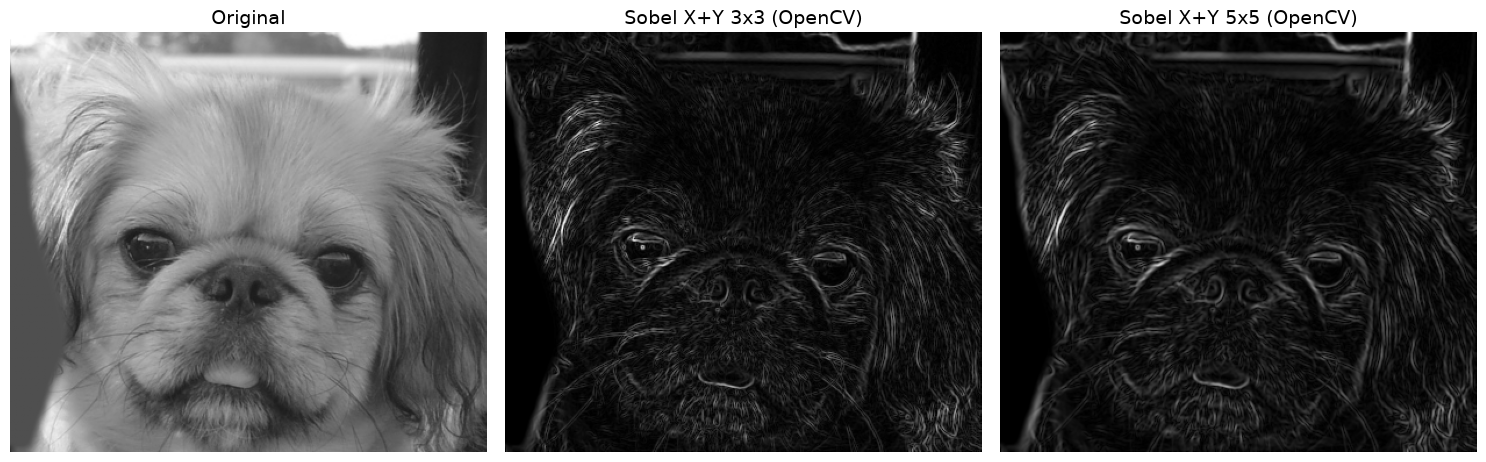

In [13]:
sobel_xy_cv_5x5 = sobel_xy_cv(img_gray, 5)
print("Max difference manual vs OpenCV (5x5):", np.abs(sobel_xy_5x5 - sobel_xy_cv_5x5).max())

show_row([img_gray, to_display(sobel_xy_cv_3x3), to_display(sobel_xy_cv_5x5)],
         ["Original", "Sobel X+Y 3x3 (OpenCV)", "Sobel X+Y 5x5 (OpenCV)"], "ex6_sobel_xy_opencv.png")

**Discussion:** OpenCV matches my manual implementation exactly (max difference 0.0 for 3x3 and 5x5), so the kernels and border handling are the same.

---
## Exercise 7 — Gaussian Filter (OpenCV)

Apply `cv2.GaussianBlur`.

### 7.1 — 3x3 Kernel

Apply `cv2.GaussianBlur` with a **3x3** kernel.

In [14]:
gauss_3x3 = gaussian_cv(img_gray, 3)
print(cv2.getGaussianKernel(3, 0).ravel())

[0.25 0.5  0.25]


### 7.2 — 5x5 Kernel

Apply `cv2.GaussianBlur` with a **5x5** kernel.

[0.0625 0.25   0.375  0.25   0.0625]


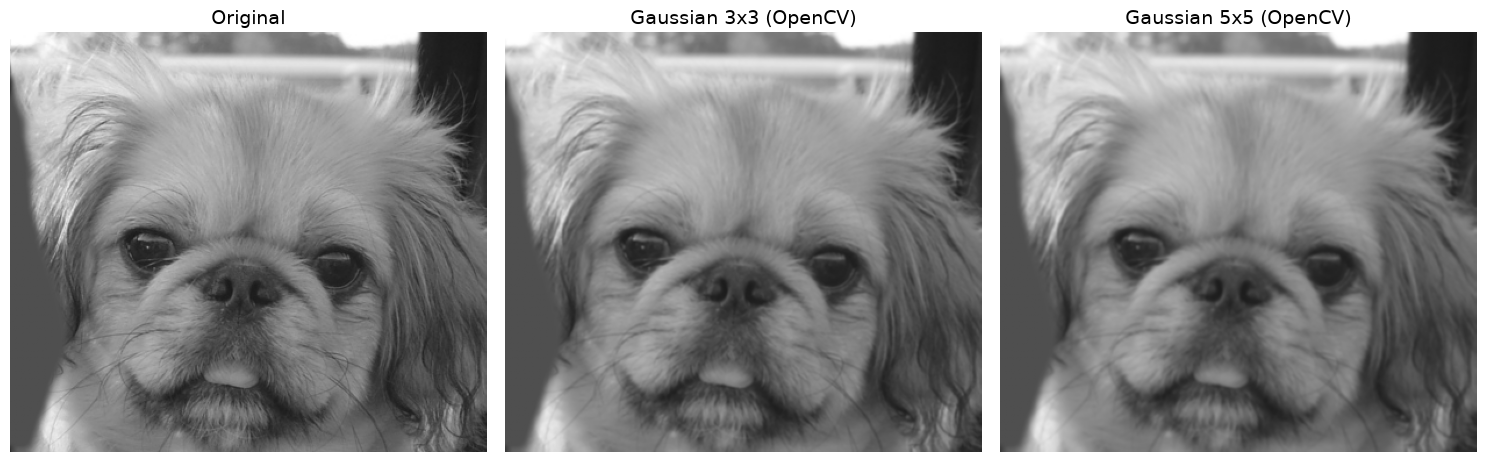

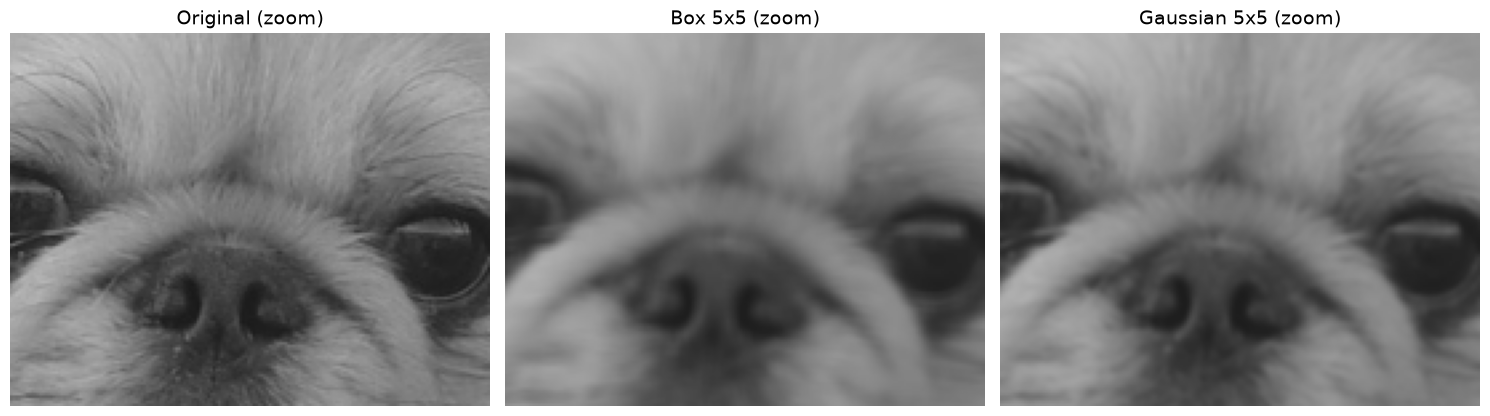

In [15]:
gauss_5x5 = gaussian_cv(img_gray, 5)
print(cv2.getGaussianKernel(5, 0).ravel())

show_row([img_gray, gauss_3x3, gauss_5x5], ["Original", "Gaussian 3x3 (OpenCV)", "Gaussian 5x5 (OpenCV)"], "ex7_gaussian.png")
# Box vs Gaussian at the same 5x5 size, zoomed in
show_row([img_gray, box_cv_5x5, gauss_5x5], ["Original (zoom)", "Box 5x5 (zoom)", "Gaussian 5x5 (zoom)"], "ex7_box_vs_gaussian_zoom.png", zoom=(120, 260, 120, 300))

**Discussion:** With the same kernel size, the Gaussian blurs less than the box filter and keeps edges more natural, because the center pixel has the largest weight while the box filter weighs every pixel equally.

## Overall Discussion

See Chapter 4 of the report. Main challenges: understanding the sliding window and the element-wise multiply-and-sum (a dot product of the window and the kernel), padding the borders, and keeping values in float until the end to avoid uint8 overflow.